# NBA Shot Prediction Using Machine Learning

## Project Overview

This project uses machine learning to predict the probability of an NBA player successfully making a shot. The goal was to understand how different factors, such as shot distance, defensive pressure, shot type, and player movement, influence shooting success.

Using Python and machine learning techniques, I analyzed over **425,000 NBA shot attempts** to build a model that estimates the likelihood of a shot going in.

## Data Analysis

The dataset included information about individual shot attempts across multiple NBA seasons. I explored several factors that could influence shot outcomes, including:

- **Shot Distance:** How far the player was from the basket.
- **Defender Distance:** How close the nearest defender was to the shooter.
- **Shot Type:** Whether the attempt was a layup, dunk, jumper, floater, or another type of shot.
- **Shot Clock:** How much time remained when the shot was attempted.
- **Player Movement:** The shooter's speed and number of dribbles before shooting.
- **Defensive Pressure:** The number of defenders contesting the shot.

I also created additional features to explore relationships between these variables, such as how shooting distance and player speed interact.

## Machine Learning Model

I used Python and Scikit-learn to develop a **Gradient Boosting Classifier**, a machine learning algorithm that combines multiple decision trees to make predictions.

The model was trained on historical NBA shot data and evaluated using three performance metrics:

- **Accuracy:** Measures how often the model correctly predicts whether a shot is made or missed.
- **ROC AUC:** Measures how effectively the model distinguishes between successful and unsuccessful shots.
- **Log Loss:** Evaluates how accurate the model's predicted probabilities are.

I also experimented with feature engineering and hyperparameter tuning to compare different model configurations and identify which performed best.

## Model Results

The selected model achieved the following results during validation:

| Metric | Result |
|---|---|
| Accuracy | 63.35% |
| ROC AUC | 0.6622 |
| Log Loss | 0.6322 |

These results show that the model can identify patterns associated with shot success, although there is still room to improve its predictive accuracy.

The final model was trained using the available training dataset and generated shot success probabilities for **213,977 additional shot attempts**.

## Tools and Technologies

- **Python:** Data processing and machine learning development.
- **Pandas and NumPy:** Data cleaning, preparation, and analysis.
- **Scikit learn:** Model training, evaluation, and optimization.
- **Matplotlib:** Visualizing and comparing model performance.
- **Google Colab:** Developing and running the project.
- **Joblib:** Saving and reloading the trained model.

## Project Takeaways

This project helped me gain practical experience in sports analytics, machine learning, feature engineering, and model evaluation.

One of the most important parts of the project was learning how to compare models using more than just accuracy. By evaluating predicted probabilities and testing different features, I gained a better understanding of how machine learning can be applied to real basketball data.

Overall, the project demonstrates how data can be used to analyze shooting patterns, estimate shot success probabilities, and support basketball performance analysis.

### Load the datasets

Import Pandas and load the training and testing shot datasets. Print their dimensions to confirm they loaded correctly.


In [ ]:

import pandas as pd

train = pd.read_csv("training.csv.gz")
test = pd.read_csv("testing.csv.gz")

print("Training data:", train.shape)
print("Testing data:", test.shape)


Training data: (425719, 29)
Testing data: (213977, 28)


### Preview the training data

Display the first few rows to see what one shot record looks like.

In [ ]:

train.head()


,shot_id,outcome,season_id,off_team_id,def_team_id,shooter_id,closestdef_id,num_contesters,contester1_id,contester2_id,...,shottype,distance,locationx,locationy,three,dribblesbefore,shotclock,closestdefdist,closestdefapproach,shooterspeed
0,2,False,fe055,b25360,374b0a,8f2113635e,c84ddbc387,0,NaN,NaN,...,jumper,24.794001,-21.91,14.87,True,1,20.57,11.332678,"{20.0470047638,18.8207810677,16.568961947,13.8...",2.386667
1,3,True,2676a,82f2ae,1f6160,c41ce2b6ec,e6e50816d4,1,e6e50816d4,NaN,...,jumper,16.458630,-34.91,-14.97,False,2,6.64,2.969714,"{5.5902504416,5.3995647973,4.9714786533,4.0232...",4.470777
2,4,True,2676a,1f6160,9dd789,90c89ca866,5318b35f44,2,5318b35f44,6484b807e1,...,layup,6.355289,-40.31,-6.19,False,2,14.31,2.556345,"{1.7779201332,0.4825971405,0.2961418579,2.1266...",8.414604
3,7,True,2676a,7831ab,188c02,fcf6c715f3,6a403360ae,0,NaN,NaN,...,dunk,2.310087,-39.61,-0.87,False,0,20.65,3.689255,"{8.6818258448,7.0713860028,5.388970217,3.55443...",12.971724
4,9,True,2676a,82f2ae,791f8d,7ff33cf9e0,fb6bcd9f22,1,fb6bcd9f22,NaN,...,jumper,24.959908,-32.32,23.11,True,0,18.87,9.199810,"{20.1202485074,17.8820244939,14.6324707415,11....",0.041667


### Check the available columns

Print the column names to understand which variables are available for analysis.

In [ ]:

print(train.columns.tolist())


['shot_id', 'outcome', 'season_id', 'off_team_id', 'def_team_id', 'shooter_id', 'closestdef_id', 'num_contesters', 'contester1_id', 'contester2_id', 'contester3_id', 'contester4_id', 'distcont1', 'distcont2', 'distcont3', 'distcont4', 'contested', 'month', 'gamestate', 'shottype', 'distance', 'locationx', 'locationy', 'three', 'dribblesbefore', 'shotclock', 'closestdefdist', 'closestdefapproach', 'shooterspeed']


### Review each variable

List each column separately to make the dataset easier to inspect.

In [ ]:

for column in train.columns:
    print(column)


shot_id
outcome
season_id
off_team_id
def_team_id
shooter_id
closestdef_id
num_contesters
contester1_id
contester2_id
contester3_id
contester4_id
distcont1
distcont2
distcont3
distcont4
contested
month
gamestate
shottype
distance
locationx
locationy
three
dribblesbefore
shotclock
closestdefdist
closestdefapproach
shooterspeed


### Analyze shot types

Calculate the number of attempts and shooting percentage for each shot type.


In [ ]:

shot_types = train.groupby("shottype")["outcome"].agg(["mean", "count"])

shot_types["shooting_percentage"] = shot_types["mean"] * 100

print(shot_types.sort_values("shooting_percentage", ascending=False))


              mean   count  shooting_percentage
shottype                                       
dunk      0.885396   25767            88.539605
layup     0.535159  115446            53.515930
tip       0.481221    9372            48.122066
post      0.453702   14774            45.370245
floater   0.416859   27700            41.685921
jumper    0.378104  231542            37.810419
heave     0.094812    1118             9.481216


### Visualize shooting percentage by shot type

Create a bar chart comparing shooting percentages across shot types.

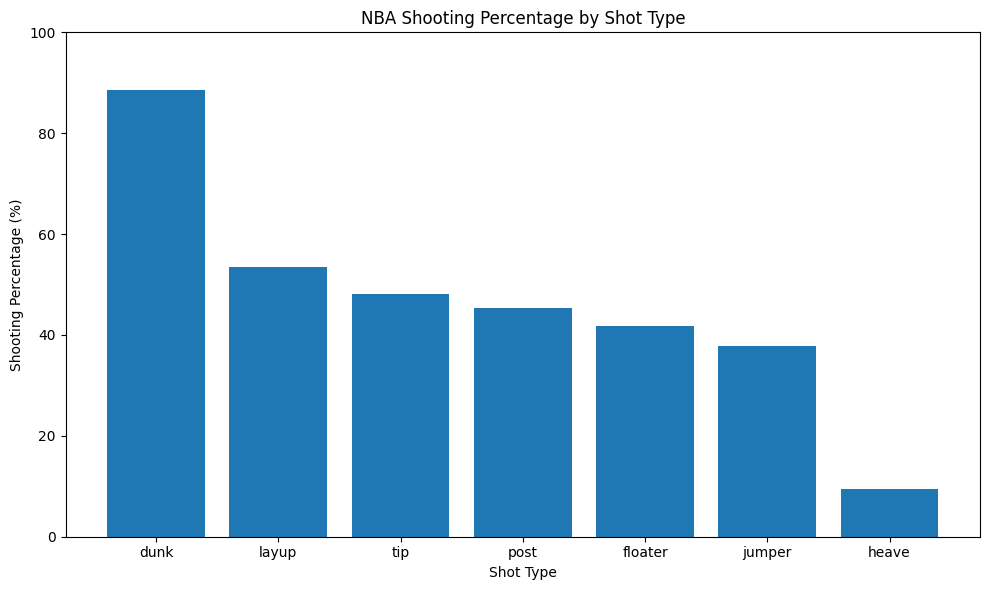

In [ ]:

import matplotlib.pyplot as plt

shot_types = shot_types.sort_values("shooting_percentage", ascending=False)

plt.figure(figsize=(10, 6))

plt.bar(shot_types.index, shot_types["shooting_percentage"])

plt.title("NBA Shooting Percentage by Shot Type")
plt.xlabel("Shot Type")
plt.ylabel("Shooting Percentage (%)")

plt.ylim(0, 100)
plt.tight_layout()
plt.show()


### Group shots by distance

Divide shot distances into ranges and calculate the shooting percentage in each range.

In [ ]:

import numpy as np

distance_bins = [0, 5, 10, 15, 20, 25, 30, 100]

train["distance_group"] = pd.cut(
    train["distance"],
    bins=distance_bins,
    include_lowest=True
)

distance_analysis = train.groupby(
    "distance_group", observed=True
)["outcome"].agg(["mean", "count"])

distance_analysis["shooting_percentage"] = distance_analysis["mean"] * 100

print(distance_analysis)


                    mean   count  shooting_percentage
distance_group                                       
(-0.001, 5.0]   0.635502  124832            63.550211
(5.0, 10.0]     0.411274   53772            41.127353
(10.0, 15.0]    0.438951   37052            43.895066
(15.0, 20.0]    0.416901   26011            41.690054
(20.0, 25.0]    0.377259   85782            37.725863
(25.0, 30.0]    0.352000   94713            35.200025
(30.0, 100.0]   0.211976    3557            21.197638


### Visualize shooting percentage by distance

Plot shooting percentage across distance groups to examine how shooting changes farther from the basket.

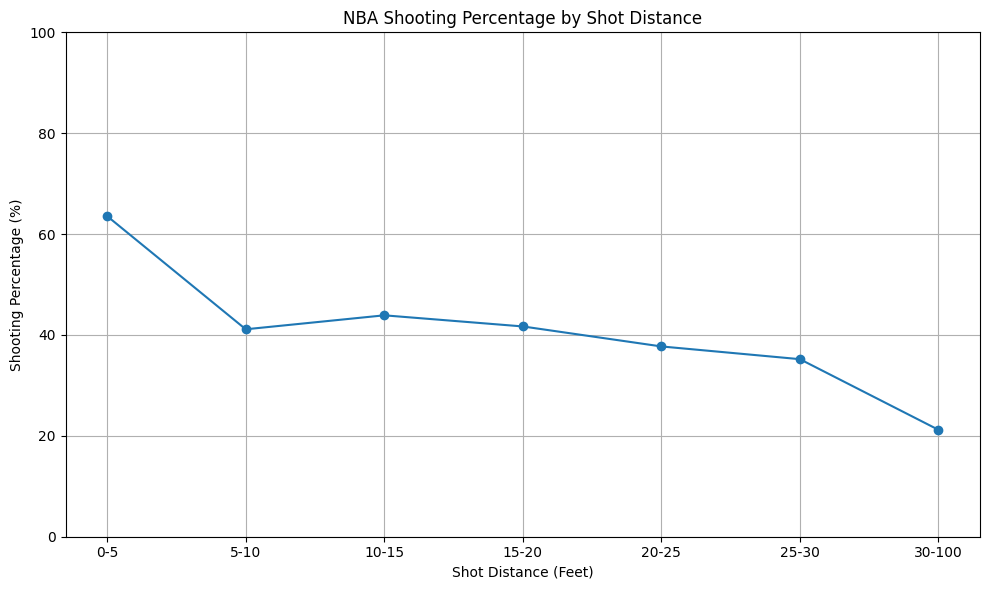

In [ ]:

plt.figure(figsize=(10, 6))

plt.plot(
    range(len(distance_analysis)),
    distance_analysis["shooting_percentage"],
    marker="o"
)

plt.xticks(
    range(len(distance_analysis)),
    ["0-5", "5-10", "10-15", "15-20", "20-25", "25-30", "30-100"]
)

plt.title("NBA Shooting Percentage by Shot Distance")
plt.xlabel("Shot Distance (Feet)")
plt.ylabel("Shooting Percentage (%)")

plt.ylim(0, 100)
plt.grid(True)
plt.tight_layout()
plt.show()


### Analyze defender proximity

Group shots by the distance to the closest defender and summarize shooting success.

In [ ]:

defender_bins = [0, 2, 4, 6, 8, 10, 100]

train["defender_group"] = pd.cut(
    train["closestdefdist"],
    bins=defender_bins,
    include_lowest=True
)

defender_analysis = train.groupby(
    "defender_group", observed=True
)["outcome"].agg(["mean", "count"])

defender_analysis["shooting_percentage"] = defender_analysis["mean"] * 100

print(defender_analysis)


                    mean   count  shooting_percentage
defender_group                                       
(-0.001, 2.0]   0.424608   28080            42.460826
(2.0, 4.0]      0.499660  163435            49.966042
(4.0, 6.0]      0.441065  127734            44.106503
(6.0, 8.0]      0.416133   63684            41.613278
(8.0, 10.0]     0.424204   23161            42.420448
(10.0, 100.0]   0.446318   19625            44.631847


### Examine contested jump shots

Focus on jump shots and compare shooting percentages across defender-distance groups.

In [ ]:

jumpers = train[train["shottype"] == "jumper"].copy()

jumper_defense = jumpers.groupby(
    "defender_group", observed=True
)["outcome"].agg(["mean", "count"])

jumper_defense["shooting_percentage"] = jumper_defense["mean"] * 100

print(jumper_defense)


                    mean  count  shooting_percentage
defender_group                                      
(-0.001, 2.0]   0.306716   1340            30.671642
(2.0, 4.0]      0.340189  33208            34.018911
(4.0, 6.0]      0.373380  97544            37.338022
(6.0, 8.0]      0.388488  59101            38.848750
(8.0, 10.0]     0.403040  22040            40.303993
(10.0, 100.0]   0.413731  18309            41.373095


### Check missing training values

Count missing values in each training data column before preparing the model.

In [ ]:

missing_values = train.isnull().sum()

print(missing_values)


shot_id                    0
outcome                    0
season_id                  0
off_team_id                0
def_team_id                0
shooter_id                 0
closestdef_id              0
num_contesters             0
contester1_id          46007
contester2_id         356016
contester3_id         421653
contester4_id         425682
distcont1              46007
distcont2             356016
distcont3             421653
distcont4             425682
contested                  0
month                      0
gamestate                  0
shottype                   0
distance                   0
locationx                  0
locationy                  0
three                      0
dribblesbefore             0
shotclock                  0
closestdefdist             0
closestdefapproach         0
shooterspeed               0
distance_group             0
defender_group             0
dtype: int64


### Check missing testing values

Identify missing values in the testing dataset so the same preprocessing can be applied.

In [ ]:

test_missing = test.isnull().sum()

print(test_missing[test_missing > 0])


contester1_id     24086
contester2_id    180408
contester3_id    212121
contester4_id    213964
distcont1         24086
distcont2        180408
distcont3        212121
distcont4        213964
dtype: int64


### Select modeling features

Choose the shot-related inputs and target variable used to train the prediction model.

In [ ]:

features = [
    "distance",
    "closestdefdist",
    "closestdefapproach",
    "shooterspeed",
    "shotclock",
    "dribblesbefore",
    "num_contesters",
    "three",
    "contested",
    "shottype"
]

X = train[features].copy()
y = train["outcome"].astype(int)

print("Input data:", X.shape)
print("Target data:", y.shape)
print(X.head())


Input data: (425719, 10)
Target data: (425719,)
    distance  closestdefdist  \
0  24.794001       11.332678   
1  16.458630        2.969714   
2   6.355289        2.556345   
3   2.310087        3.689255   
4  24.959908        9.199810   

                                  closestdefapproach  shooterspeed  shotclock  \
0  {20.0470047638,18.8207810677,16.568961947,13.8...      2.386667      20.57   
1  {5.5902504416,5.3995647973,4.9714786533,4.0232...      4.470777       6.64   
2  {1.7779201332,0.4825971405,0.2961418579,2.1266...      8.414604      14.31   
3  {8.6818258448,7.0713860028,5.388970217,3.55443...     12.971724      20.65   
4  {20.1202485074,17.8820244939,14.6324707415,11....      0.041667      18.87   

   dribblesbefore  num_contesters  three  contested shottype  
0               1               0   True      False   jumper  
1               2               1  False       True   jumper  
2               2               2  False       True    layup  
3               0   

### Encode shot types

Remove a selected variable and convert shot-type categories into numeric indicator columns.

In [ ]:

X = X.drop(columns=["closestdefapproach"])

X = pd.get_dummies(X, columns=["shottype"], dtype=int)

print("New input shape:", X.shape)
print(X.head())


New input shape: (425719, 15)
    distance  closestdefdist  shooterspeed  shotclock  dribblesbefore  \
0  24.794001       11.332678      2.386667      20.57               1   
1  16.458630        2.969714      4.470777       6.64               2   
2   6.355289        2.556345      8.414604      14.31               2   
3   2.310087        3.689255     12.971724      20.65               0   
4  24.959908        9.199810      0.041667      18.87               0   

   num_contesters  three  contested  shottype_dunk  shottype_floater  \
0               0   True      False              0                 0   
1               1  False       True              0                 0   
2               2  False       True              0                 0   
3               0  False      False              1                 0   
4               1   True       True              0                 0   

   shottype_heave  shottype_jumper  shottype_layup  shottype_post  \
0               0            

### Confirm numeric input data

Convert boolean features to integers and check data types and remaining missing values.

In [ ]:

X["three"] = X["three"].astype(int)
X["contested"] = X["contested"].astype(int)

print(X.dtypes)
print("Missing values:", X.isnull().sum().sum())


distance            float64
closestdefdist      float64
shooterspeed        float64
shotclock           float64
dribblesbefore        int64
num_contesters        int64
three                 int64
contested             int64
shottype_dunk         int64
shottype_floater      int64
shottype_heave        int64
shottype_jumper       int64
shottype_layup        int64
shottype_post         int64
shottype_tip          int64
dtype: object
Missing values: 0


### Create a training and validation split

Separate the available labeled data into training and validation sets for initial model testing.

In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training inputs:", X_train.shape)
print("Validation inputs:", X_val.shape)
print("Training answers:", y_train.shape)
print("Validation answers:", y_val.shape)


Training inputs: (340575, 15)
Validation inputs: (85144, 15)
Training answers: (340575,)
Validation answers: (85144,)


### Train a logistic regression model

Build a scaled logistic regression model as an initial machine learning benchmark.

In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

print("Model training complete!")


Model training complete!


### Evaluate logistic regression

Calculate accuracy, ROC AUC, and log loss to measure the model’s performance.

In [ ]:

from sklearn.metrics import accuracy_score, roc_auc_score, log_loss

y_pred = model.predict(X_val)

y_prob = model.predict_proba(X_val)[:, 1]

accuracy = accuracy_score(y_val, y_pred)
auc = roc_auc_score(y_val, y_prob)
loss = log_loss(y_val, y_prob)

print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("ROC AUC:", round(auc, 4))
print("Log Loss:", round(loss, 4))


Model Accuracy: 62.35 %
ROC AUC: 0.6486
Log Loss: 0.6425


### Compare against simple baselines

Evaluate basic prediction strategies to see whether machine learning improves on simple guesses.

In [ ]:

import numpy as np
from sklearn.metrics import accuracy_score, log_loss

baseline_prob = y_train.mean()

baseline_predictions = np.zeros(len(y_val), dtype=int)

baseline_accuracy = accuracy_score(y_val, baseline_predictions)

baseline_probs = np.full(len(y_val), baseline_prob)

baseline_loss = log_loss(y_val, baseline_probs)

print("Baseline Accuracy:", round(baseline_accuracy * 100, 2), "%")
print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("Baseline Log Loss:", round(baseline_loss, 4))
print("Model Log Loss:", round(loss, 4))


Baseline Accuracy: 54.19 %
Model Accuracy: 62.35 %
Baseline Log Loss: 0.6896
Model Log Loss: 0.6425


### Train gradient boosting

Train a Histogram-Based Gradient Boosting model and evaluate its predictions.


In [ ]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss

advanced_model = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

advanced_model.fit(X_train, y_train)

advanced_pred = advanced_model.predict(X_val)
advanced_prob = advanced_model.predict_proba(X_val)[:, 1]

advanced_accuracy = accuracy_score(y_val, advanced_pred)
advanced_auc = roc_auc_score(y_val, advanced_prob)
advanced_loss = log_loss(y_val, advanced_prob)

print("Advanced Model Accuracy:", round(advanced_accuracy * 100, 2), "%")
print("Advanced Model ROC AUC:", round(advanced_auc, 4))
print("Advanced Model Log Loss:", round(advanced_loss, 4))


Advanced Model Accuracy: 63.59 %
Advanced Model ROC AUC: 0.6631
Advanced Model Log Loss: 0.6309


### Measure feature importance

Use permutation importance on a validation sample to estimate which inputs matter most to the trained model.

In [ ]:

from sklearn.inspection import permutation_importance
import pandas as pd

sample_X = X_val.sample(n=10000, random_state=42)
sample_y = y_val.loc[sample_X.index]

importance = permutation_importance(
    advanced_model,
    sample_X,
    sample_y,
    scoring="neg_log_loss",
    n_repeats=3,
    random_state=42
)

importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": importance.importances_mean
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print(importance_df)


             Feature  Importance
0           distance    0.142041
1     closestdefdist    0.018522
8      shottype_dunk    0.009179
2       shooterspeed    0.008988
5     num_contesters    0.007134
12    shottype_layup    0.001931
4     dribblesbefore    0.001763
3          shotclock    0.001538
14      shottype_tip    0.000370
13     shottype_post    0.000057
9   shottype_floater    0.000034
10    shottype_heave    0.000000
7          contested    0.000000
11   shottype_jumper   -0.000005
6              three   -0.000100


### Plot important features

Visualize the highest-ranked features from the permutation-importance analysis.

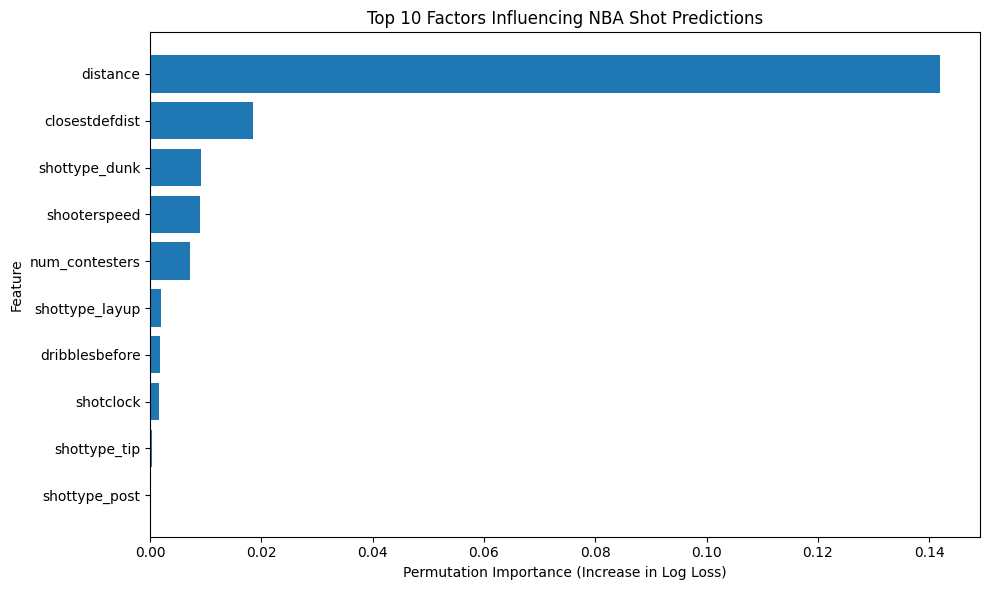

In [ ]:

import matplotlib.pyplot as plt

top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Factors Influencing NBA Shot Predictions")
plt.xlabel("Permutation Importance (Increase in Log Loss)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


### Prepare the testing features

Apply compatible feature transformations to the testing data and align its columns with the model inputs.

In [ ]:

test_features = test[features].copy()

test_features = test_features.drop(columns=["closestdefapproach"])

test_features = pd.get_dummies(
    test_features,
    columns=["shottype"],
    dtype=int
)

test_features = test_features.reindex(
    columns=X_train.columns,
    fill_value=0
)

test_features["three"] = test_features["three"].astype(int)
test_features["contested"] = test_features["contested"].astype(int)

print("Testing data shape:", test_features.shape)
print("Missing values:", test_features.isnull().sum().sum())


Testing data shape: (213977, 15)
Missing values: 0


### Predict testing probabilities

Use the trained gradient boosting model to estimate the probability of each testing shot being made.


In [ ]:

test_probabilities = advanced_model.predict_proba(test_features)[:, 1]

print("Number of predictions:", len(test_probabilities))
print("First 10 predictions:")
print(test_probabilities[:10])


Number of predictions: 213977
First 10 predictions:
[0.36091693 0.60413469 0.43865747 0.52278747 0.38846356 0.3494268
 0.33023887 0.33657874 0.4796424  0.35556386]


### Inspect testing identifiers

Check testing columns and example rows before assembling a prediction file.

In [ ]:

print("Test columns:")
print(test.columns.tolist())

print("First 5 rows:")
print(test.head())


Test columns:
['shot_id', 'season_id', 'off_team_id', 'def_team_id', 'shooter_id', 'closestdef_id', 'num_contesters', 'contester1_id', 'contester2_id', 'contester3_id', 'contester4_id', 'distcont1', 'distcont2', 'distcont3', 'distcont4', 'contested', 'month', 'gamestate', 'shottype', 'distance', 'locationx', 'locationy', 'three', 'dribblesbefore', 'shotclock', 'closestdefdist', 'closestdefapproach', 'shooterspeed']
First 5 rows:
   shot_id season_id off_team_id def_team_id  shooter_id closestdef_id  \
0        1     d7a2d      e801cc      16981c  45a36b40c8    c97e433df4   
1        5     d7a2d      b25360      5ab44a  2cb9af8508    9f12db4242   
2        6     d7a2d      82f2ae      28049c  90b1c72e19    b25b22c4c2   
3        8     d7a2d      16981c      c3d95c  c40278f00f    eab37a8ca6   
4       10     d7a2d      08555d      28049c  46a7a7ad66    0e1a8257a8   

   num_contesters contester1_id contester2_id contester3_id  ... shottype  \
0               1    c97e433df4           NaN

### Create an initial submission table

Pair shot identifiers with predicted probabilities in an initial submission DataFrame.


In [ ]:

submission = pd.DataFrame({
    "shot_id": test["shot_id"],
    "outcome": test_probabilities
})

print(submission.head())
print("Submission shape:", submission.shape)


   shot_id   outcome
0        1  0.360917
1        5  0.604135
2        6  0.438657
3        8  0.522787
4       10  0.388464
Submission shape: (213977, 2)


### Save an initial model and results

Save the trained model and an initial summary of its performance.

In [ ]:

import joblib
import pandas as pd

joblib.dump(advanced_model, "nba_gradient_boosting_baseline.joblib")

baseline_results = pd.DataFrame({
    "Model": ["Gradient Boosting Baseline"],
    "Accuracy": [advanced_accuracy],
    "ROC_AUC": [advanced_auc],
    "Log_Loss": [advanced_loss]
})

print("Baseline model saved successfully!")
print(baseline_results)


Baseline model saved successfully!
                        Model  Accuracy   ROC_AUC  Log_Loss
0  Gradient Boosting Baseline  0.635852  0.663052  0.630924


### Review dataset and season sizes

Summarize the datasets, available seasons, and overall shot outcomes.

In [ ]:

print("Training dataset:", train.shape)
print("Testing dataset:", test.shape)

print("\nSeasons in training data:")
print(train["season_id"].value_counts())

print("\nSeasons in testing data:")
print(test["season_id"].value_counts())

print("\nUnique shooters in training:")
print(train["shooter_id"].nunique())

print("\nUnique shooters in testing:")
print(test["shooter_id"].nunique())

print("\nAverage shot success rate:")
print(train["outcome"].mean() * 100)


Training dataset: (425719, 31)
Testing dataset: (213977, 28)

Seasons in training data:
season_id
fe055    213261
2676a    212458
Name: count, dtype: int64

Seasons in testing data:
season_id
d7a2d    213977
Name: count, dtype: int64

Unique shooters in training:
767

Unique shooters in testing:
566

Average shot success rate:
45.80697596301786


### Inspect season labels

Check the season identifiers to prepare a validation strategy based on different seasons.

In [ ]:

print("Training seasons:")
print(train["season_id"].value_counts())

print("\nSeason labels:")
print(train["season_id"].unique())

print("\nCurrent feature columns:")
print(X.columns.tolist())

print("\nModel settings:")
print(advanced_model.get_params())


Training seasons:
season_id
fe055    213261
2676a    212458
Name: count, dtype: int64

Season labels:
['fe055' '2676a']

Current feature columns:
['distance', 'closestdefdist', 'shooterspeed', 'shotclock', 'dribblesbefore', 'num_contesters', 'three', 'contested', 'shottype_dunk', 'shottype_floater', 'shottype_heave', 'shottype_jumper', 'shottype_layup', 'shottype_post', 'shottype_tip']

Model settings:
{'categorical_features': 'from_dtype', 'class_weight': None, 'early_stopping': 'auto', 'interaction_cst': None, 'l2_regularization': 0.0, 'learning_rate': 0.1, 'loss': 'log_loss', 'max_bins': 255, 'max_depth': None, 'max_features': 1.0, 'max_iter': 150, 'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'monotonic_cst': None, 'n_iter_no_change': 10, 'random_state': 42, 'scoring': 'loss', 'tol': 1e-07, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}


### Evaluate on a separate season

Train on one season and validate on another to assess performance on a different time period.

In [ ]:

from sklearn.base import clone
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss

season_train_mask = train["season_id"] == "fe055"
season_val_mask = train["season_id"] == "2676a"

X_season_train = X.loc[season_train_mask]
y_season_train = y.loc[season_train_mask]

X_season_val = X.loc[season_val_mask]
y_season_val = y.loc[season_val_mask]

season_model = clone(advanced_model)

season_model.fit(X_season_train, y_season_train)

season_predictions = season_model.predict(X_season_val)
season_probabilities = season_model.predict_proba(X_season_val)[:, 1]

print("Season Validation Results")
print("Training shots:", len(X_season_train))
print("Validation shots:", len(X_season_val))

print("Accuracy:", round(accuracy_score(y_season_val, season_predictions) * 100, 2), "%")
print("ROC AUC:", round(roc_auc_score(y_season_val, season_probabilities), 4))
print("Log Loss:", round(log_loss(y_season_val, season_probabilities), 4))


Season Validation Results
Training shots: 213261
Validation shots: 212458
Accuracy: 63.32 %
ROC AUC: 0.662
Log Loss: 0.6323


### Engineer basketball features

Create additional shot-related variables that may capture nonlinear relationships or interactions.

In [ ]:

def add_basketball_features(data):
    data = data.copy()

    data["distance_squared"] = data["distance"] ** 2

    data["defender_pressure"] = 1 / (data["closestdefdist"] + 1)

    data["distance_defender_interaction"] = (
        data["distance"] * data["closestdefdist"]
    )

    data["speed_distance_interaction"] = (
        data["shooterspeed"] * data["distance"]
    )

    data["late_shotclock"] = (
        data["shotclock"] < 5
    ).astype(int)

    return data

X_improved = add_basketball_features(X)

print("Original number of features:", X.shape[1])
print("New number of features:", X_improved.shape[1])

print(X_improved.head())


Original number of features: 15
New number of features: 20
    distance  closestdefdist  shooterspeed  shotclock  dribblesbefore  \
0  24.794001       11.332678      2.386667      20.57               1   
1  16.458630        2.969714      4.470777       6.64               2   
2   6.355289        2.556345      8.414604      14.31               2   
3   2.310087        3.689255     12.971724      20.65               0   
4  24.959908        9.199810      0.041667      18.87               0   

   num_contesters  three  contested  shottype_dunk  shottype_floater  \
0               0      1          0              0                 0   
1               1      0          1              0                 0   
2               2      0          1              0                 0   
3               0      0          0              1                 0   
4               1      1          1              0                 0   

   shottype_heave  shottype_jumper  shottype_layup  shottype_post  \


### Test engineered features

Evaluate the expanded feature set to see whether the added variables improve prediction quality.

In [ ]:

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss

X_train_improved, X_val_improved, y_train_improved, y_val_improved = train_test_split(
    X_improved,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

improved_model = clone(advanced_model)

improved_model.fit(X_train_improved, y_train_improved)

improved_predictions = improved_model.predict(X_val_improved)

improved_probabilities = improved_model.predict_proba(X_val_improved)[:, 1]

improved_accuracy = accuracy_score(y_val_improved, improved_predictions)
improved_auc = roc_auc_score(y_val_improved, improved_probabilities)
improved_loss = log_loss(y_val_improved, improved_probabilities)

print("Improved Model Results")
print("Accuracy:", round(improved_accuracy * 100, 2), "%")
print("ROC AUC:", round(improved_auc, 4))
print("Log Loss:", round(improved_loss, 4))


Improved Model Results
Accuracy: 63.61 %
ROC AUC: 0.6639
Log Loss: 0.6307


### Compare feature sets by season

Use season-based validation to compare the original and engineered features.

In [ ]:

from sklearn.base import clone
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss

season_train_mask = train["season_id"] == "fe055"
season_val_mask = train["season_id"] == "2676a"

X_season_train_improved = X_improved.loc[season_train_mask]
y_season_train_improved = y.loc[season_train_mask]

X_season_val_improved = X_improved.loc[season_val_mask]
y_season_val_improved = y.loc[season_val_mask]

season_improved_model = clone(advanced_model)

season_improved_model.fit(
    X_season_train_improved,
    y_season_train_improved
)

season_improved_predictions = season_improved_model.predict(
    X_season_val_improved
)

season_improved_probabilities = season_improved_model.predict_proba(
    X_season_val_improved
)[:, 1]

print("Improved Season Validation Results")

print("Accuracy:", round(
    accuracy_score(y_season_val_improved, season_improved_predictions) * 100, 2
), "%")

print("ROC AUC:", round(
    roc_auc_score(y_season_val_improved, season_improved_probabilities), 4
))

print("Log Loss:", round(
    log_loss(y_season_val_improved, season_improved_probabilities), 4
))


Improved Season Validation Results
Accuracy: 63.28 %
ROC AUC: 0.6607
Log Loss: 0.6328


### Test engineered features individually

Measure how individual engineered features affect model performance.

In [ ]:

from sklearn.base import clone
from sklearn.metrics import log_loss, roc_auc_score, accuracy_score
import pandas as pd

new_features = [
    "distance_squared",
    "defender_pressure",
    "distance_defender_interaction",
    "speed_distance_interaction",
    "late_shotclock"
]

results = []

feature_sets = {
    "Original 15 Features": list(X.columns)
}

for feature in new_features:
    feature_sets["Original + " + feature] = list(X.columns) + [feature]

feature_sets["All 20 Features"] = list(X_improved.columns)

for name, columns in feature_sets.items():

    X_train_test = X_improved.loc[season_train_mask, columns]
    X_val_test = X_improved.loc[season_val_mask, columns]

    test_model = clone(advanced_model)
    test_model.fit(X_train_test, y_season_train_improved)

    probabilities = test_model.predict_proba(X_val_test)[:, 1]
    predictions = test_model.predict(X_val_test)

    results.append({
        "Feature Set": name,
        "Accuracy": accuracy_score(y_season_val_improved, predictions),
        "ROC AUC": roc_auc_score(y_season_val_improved, probabilities),
        "Log Loss": log_loss(y_season_val_improved, probabilities)
    })

feature_results = pd.DataFrame(results)

feature_results = feature_results.sort_values("Log Loss")

print(feature_results.to_string(index=False))


                             Feature Set  Accuracy  ROC AUC  Log Loss
   Original + speed_distance_interaction  0.633490 0.662427  0.632177
                    Original 15 Features  0.633198 0.661976  0.632318
             Original + distance_squared  0.633198 0.661976  0.632318
               Original + late_shotclock  0.633179 0.661454  0.632417
            Original + defender_pressure  0.633377 0.661719  0.632419
Original + distance_defender_interaction  0.633438 0.661501  0.632571
                         All 20 Features  0.632789 0.660748  0.632807


### Evaluate a promising interaction feature

Test a feature set that adds the speed and distance interaction to the original inputs.

In [ ]:

best_features = list(X.columns) + ["speed_distance_interaction"]

X_best = X_improved[best_features].copy()

X_best_train = X_best.loc[season_train_mask]
y_best_train = y.loc[season_train_mask]

X_best_val = X_best.loc[season_val_mask]
y_best_val = y.loc[season_val_mask]

print("Selected features:", len(best_features))
print("Training data:", X_best_train.shape)
print("Validation data:", X_best_val.shape)
print("Missing values:", X_best.isnull().sum().sum())
print("Feature names:", best_features)


Selected features: 16
Training data: (213261, 16)
Validation data: (212458, 16)
Missing values: 0
Feature names: ['distance', 'closestdefdist', 'shooterspeed', 'shotclock', 'dribblesbefore', 'num_contesters', 'three', 'contested', 'shottype_dunk', 'shottype_floater', 'shottype_heave', 'shottype_jumper', 'shottype_layup', 'shottype_post', 'shottype_tip', 'speed_distance_interaction']


### Search model settings  first pass

Try alternative gradient boosting settings and compare their validation results.

In [ ]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.metrics import log_loss, roc_auc_score
import pandas as pd

X_tune_train, X_tune_val, y_tune_train, y_tune_val = train_test_split(
    X_best_train,
    y_best_train,
    test_size=0.2,
    random_state=42,
    stratify=y_best_train
)

parameter_grid = {
    "learning_rate": [0.05, 0.1],
    "max_iter": [100, 200],
    "max_leaf_nodes": [15, 31]
}

tuning_results = []

for params in ParameterGrid(parameter_grid):
    tuned_model = HistGradientBoostingClassifier(
        **params,
        random_state=42
    )

    tuned_model.fit(X_tune_train, y_tune_train)

    probabilities = tuned_model.predict_proba(X_tune_val)[:, 1]

    tuning_results.append({
        **params,
        "Log Loss": log_loss(y_tune_val, probabilities),
        "ROC AUC": roc_auc_score(y_tune_val, probabilities)
    })

tuning_results_df = pd.DataFrame(tuning_results)
tuning_results_df = tuning_results_df.sort_values("Log Loss")

print(tuning_results_df.to_string(index=False))


 learning_rate  max_iter  max_leaf_nodes  Log Loss  ROC AUC
          0.05       200              31  0.629215 0.667919
          0.10       100              31  0.629314 0.667777
          0.10       200              31  0.629314 0.667777
          0.05       100              31  0.629327 0.668058
          0.05       200              15  0.629628 0.667515
          0.10       100              15  0.629803 0.667005
          0.10       200              15  0.629803 0.667005
          0.05       100              15  0.629891 0.667582


### Search model settings  additional pass

Continue the parameter search to identify a potentially stronger model configuration.


In [ ]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.metrics import log_loss, roc_auc_score
import pandas as pd

X_tune_train, X_tune_val, y_tune_train, y_tune_val = train_test_split(
    X_best_train,
    y_best_train,
    test_size=0.2,
    random_state=42,
    stratify=y_best_train
)

parameter_grid = {
    "learning_rate": [0.05, 0.1],
    "max_iter": [100, 200],
    "max_leaf_nodes": [15, 31]
}

tuning_results = []

for params in ParameterGrid(parameter_grid):
    tuned_model = HistGradientBoostingClassifier(
        **params,
        random_state=42
    )

    tuned_model.fit(X_tune_train, y_tune_train)

    probabilities = tuned_model.predict_proba(X_tune_val)[:, 1]

    tuning_results.append({
        **params,
        "Log Loss": log_loss(y_tune_val, probabilities),
        "ROC AUC": roc_auc_score(y_tune_val, probabilities)
    })

tuning_results_df = pd.DataFrame(tuning_results)
tuning_results_df = tuning_results_df.sort_values("Log Loss")

print(tuning_results_df.to_string(index=False))


 learning_rate  max_iter  max_leaf_nodes  Log Loss  ROC AUC
          0.05       200              31  0.629215 0.667919
          0.10       100              31  0.629314 0.667777
          0.10       200              31  0.629314 0.667777
          0.05       100              31  0.629327 0.668058
          0.05       200              15  0.629628 0.667515
          0.10       100              15  0.629803 0.667005
          0.10       200              15  0.629803 0.667005
          0.05       100              15  0.629891 0.667582


### Evaluate a tuned model

Fit the selected tuned configuration and measure its accuracy, ROC AUC, and log loss.

In [ ]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss

best_model = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=200,
    max_leaf_nodes=31,
    random_state=42
)

best_model.fit(X_best_train, y_best_train)

best_predictions = best_model.predict(X_best_val)
best_probabilities = best_model.predict_proba(X_best_val)[:, 1]

best_accuracy = accuracy_score(y_best_val, best_predictions)
best_auc = roc_auc_score(y_best_val, best_probabilities)
best_loss = log_loss(y_best_val, best_probabilities)

print("Tuned Model - Season Validation Results")
print("Accuracy:", round(best_accuracy * 100, 2), "%")
print("ROC AUC:", round(best_auc, 4))
print("Log Loss:", round(best_loss, 4))


Tuned Model - Season Validation Results
Accuracy: 63.35 %
ROC AUC: 0.6622
Log Loss: 0.6322


### Review the tuning results

Print a direct comparison of the earlier model and the tuned model.

In [ ]:

print("FINAL MODEL COMPARISON")
print("----------------------")

print("Previous Model Log Loss:", advanced_loss)
print("Tuned Model Log Loss:", best_loss)

if best_loss < advanced_loss:
    print("Winner: Tuned Model")
else:
    print("Winner: Previous Model")


FINAL MODEL COMPARISON
----------------------
Previous Model Log Loss: 0.6309244042926695
Tuned Model Log Loss: 0.6321956635153009
Winner: Previous Model


### Train the selected final model

Clone the chosen gradient boosting model and retrain it on all labeled training examples.


In [ ]:

from sklearn.base import clone

final_model = clone(advanced_model)

final_model.fit(X, y)

print("Final model trained successfully!")
print("Training shots:", len(X))
print("Features used:", X.shape[1])
print("Model:", type(final_model).__name__)


Final model trained successfully!
Training shots: 425719
Features used: 15
Model: HistGradientBoostingClassifier


### Generate final test predictions

Align the testing features and generate predicted shot success probabilities using the final model.

In [ ]:

final_test_features = test_features[X.columns].copy()

final_probabilities = final_model.predict_proba(
    final_test_features
)[:, 1]

print("Final predictions generated!")
print("Number of predictions:", len(final_probabilities))
print("Minimum probability:", final_probabilities.min())
print("Maximum probability:", final_probabilities.max())

print("\nFirst 10 predictions:")
print(final_probabilities[:10])


Final predictions generated!
Number of predictions: 213977
Minimum probability: 0.026333066781219307
Maximum probability: 0.9945985446220537

First 10 predictions:
[0.35982486 0.58147046 0.43224015 0.50933606 0.39373808 0.35404216
 0.31636038 0.34804415 0.49791447 0.35669351]


### Build and validate the final submission

Create the final shot-level prediction file and check its size, identifiers, and probability values.

In [ ]:

import pandas as pd
import numpy as np

final_submission = pd.DataFrame({
    "shot_id": test["shot_id"].to_numpy(),
    "outcome": final_probabilities
})

assert len(final_submission) == len(test)
assert final_submission["shot_id"].is_unique
assert final_submission["shot_id"].notna().all()
assert final_submission["outcome"].notna().all()
assert np.isfinite(final_submission["outcome"]).all()
assert final_submission["outcome"].between(0, 1).all()
assert final_submission.columns.tolist() == ["shot_id", "outcome"]

final_submission.to_csv("submission.csv", index=False)

print("Submission file saved successfully!")
print("Submission shape:", final_submission.shape)
print("Missing values:", final_submission.isnull().sum().sum())
print("Duplicate shot IDs:", final_submission["shot_id"].duplicated().sum())

print("\nFirst 10 rows:")
print(final_submission.head(10))


Submission file saved successfully!
Submission shape: (213977, 2)
Missing values: 0
Duplicate shot IDs: 0

First 10 rows:
   shot_id   outcome
0        1  0.359825
1        5  0.581470
2        6  0.432240
3        8  0.509336
4       10  0.393738
5       11  0.354042
6       14  0.316360
7       15  0.348044
8       16  0.497914
9       17  0.356694


### Save the final model

Save the trained model and its feature list so it can be reused later.

In [ ]:

import joblib

joblib.dump(final_model, "final_nba_shot_model.joblib")

joblib.dump(
    X.columns.tolist(),
    "model_features.joblib"
)

print("Final model saved successfully!")
print("Model features saved successfully!")
print("Number of features:", len(X.columns))


Final model saved successfully!
Model features saved successfully!
Number of features: 15


### Verify the saved model

Reload the saved model and confirm that it reproduces the same predictions.

In [ ]:

import joblib
import numpy as np

loaded_model = joblib.load("final_nba_shot_model.joblib")
loaded_features = joblib.load("model_features.joblib")

loaded_probabilities = loaded_model.predict_proba(
    final_test_features[loaded_features]
)[:, 1]

print("Model loaded successfully!")
print("Features loaded:", len(loaded_features))
print("Predictions generated:", len(loaded_probabilities))

print(
    "Predictions match original:",
    np.allclose(loaded_probabilities, final_probabilities)
)


Model loaded successfully!
Features loaded: 15
Predictions generated: 213977
Predictions match original: True


### Compare models consistently

Evaluate the original and tuned models using the same season-based validation setup.

In [ ]:

from sklearn.base import clone
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss
import pandas as pd

models_to_compare = {
    "Original Gradient Boosting": clone(advanced_model),
    "Tuned Gradient Boosting": clone(best_model)
}

comparison_results = []

for name, model in models_to_compare.items():

    model.fit(X_best_train, y_best_train)

    predictions = model.predict(X_best_val)
    probabilities = model.predict_proba(X_best_val)[:, 1]

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_best_val, predictions),
        "ROC AUC": roc_auc_score(y_best_val, probabilities),
        "Log Loss": log_loss(y_best_val, probabilities)
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values("Log Loss")

print(comparison_df.to_string(index=False))


                     Model  Accuracy  ROC AUC  Log Loss
Original Gradient Boosting  0.633490 0.662427  0.632177
   Tuned Gradient Boosting  0.633513 0.662211  0.632196


### Visualize model comparisons

Create charts comparing accuracy, ROC AUC, and log loss for the model configurations.

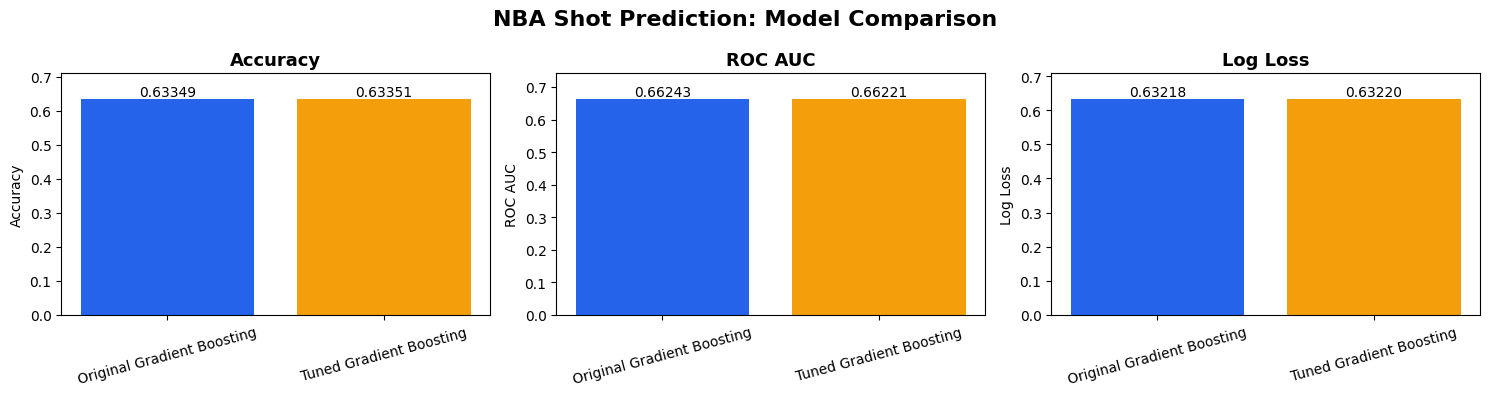

In [ ]:

import matplotlib.pyplot as plt

plot_df = comparison_df.set_index("Model")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = ["Accuracy", "ROC AUC", "Log Loss"]

for ax, metric in zip(axes, metrics):
    values = plot_df[metric]

    bars = ax.bar(
        values.index,
        values.values,
        color=["#2563eb", "#f59e0b"]
    )

    ax.set_title(metric, fontsize=13, fontweight="bold")
    ax.set_ylabel(metric)

    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{height:.5f}",
            ha="center",
            va="bottom"
        )

    ax.tick_params(axis="x", rotation=15)
    ax.set_ylim(0, values.max() * 1.12)

plt.suptitle(
    "NBA Shot Prediction: Model Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
